<a href="https://colab.research.google.com/github/Konoplyai/pattern-recognition-practice/blob/model-comparison/classification-mini-project/notebooks/PR04_Konoplia_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практичні роботи 4-7

## Мініпроєкт "Порівняння класичних моделей класифікації"

**Дисципліна:** Розпізнавання образів і машинне навчання<br>
**Студент:** Конопля Іван<br>
**Група:** ІН-42/1<br>
**Дата виконання:** 24.11.2026

### Мета роботи

Навчитися будувати відтворюваний конвеєр машинного навчання, застосовувати
класичні алгоритми класифікації, налаштовувати їхні основні гіперпараметри
та коректно порівнювати моделі за однаковими умовами без використання
тестової вибірки для підбору рішень.

## Постановка задачі

- **Об'єкт дослідження:** пацієнти, для яких виміряно клінічні показники (набір Heart Disease, Cleveland, UCI).
- **Ознаки:** 13 вхідних ознак: 5 числових (age, trestbps, chol, thalach, oldpeak) і 8 категоріальних, закодованих числами (sex, cp, fbs, restecg, exang, slope, ca, thal).
- **Цільова змінна:** `target` (0 - ознаки серцевого захворювання відсутні, 1 - ознаки наявні).
- **Кількість класів:** 2, задача бінарної класифікації з навчанням за розміченими даними.
- **Позитивний клас:** 1 (наявність ознак захворювання). Для нього обчислюються precision, recall і F1.
- **Практична мета:** за характеристиками пацієнта визначити, чи належить він до класу з наявністю ознак серцевого захворювання.
- **Основна метрика (обрана до експериментів):** CV F1 для класу 1. Додаткові метрики: CV ROC AUC і CV Recall, бо пропуск хворого пацієнта небезпечніший за хибну тривогу.
- **Правило вибору фінальної моделі:** найбільший середній CV F1; якщо різниця між кандидатами менша за 0.01, перевага надається моделі з меншим стандартним відхиленням F1, а далі простішій та інтерпретованішій.

**Етичне застереження.** Результати цього навчального мініпроєкту не є медичним діагнозом і не повинні використовуватися для клінічних рішень.

# ЧАСТИНА I. ПРАКТИЧНА РОБОТА 4
## Підготовка даних, Pipeline і логістична регресія

### 1. Підключення бібліотек і загальні налаштування

In [1]:
import time
import shutil
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

RANDOM_STATE = 42
POSITIVE_CLASS = 1
PRIMARY_METRIC = "f1"

SKLEARN_VERSION = tuple(int(p) for p in sklearn.__version__.split(".")[:2])
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

print("scikit-learn:", sklearn.__version__)
print("Позитивний клас:", POSITIVE_CLASS)
print("Основна метрика:", PRIMARY_METRIC)

scikit-learn: 1.6.1
Позитивний клас: 1
Основна метрика: f1


In [2]:
PROJECT_DIR = Path("classification-mini-project")

DATA_URL = (
    "https://raw.githubusercontent.com/Konoplyai/"
    "pattern-recognition-practice/model-comparison/"
    "classification-mini-project/data/heart_disease.csv"
)
LOCAL_DATA_PATH = PROJECT_DIR / "data" / "heart_disease.csv"

MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "best_classifier.joblib"
CV_TABLE_PATH = REPORTS_DIR / "cv_model_comparison.csv"
TEST_METRICS_PATH = REPORTS_DIR / "final_test_metrics.csv"

DATA_SOURCE = LOCAL_DATA_PATH if LOCAL_DATA_PATH.exists() else DATA_URL
print("Джерело даних:", DATA_SOURCE)
print("Файл моделі:", MODEL_PATH)

Джерело даних: https://raw.githubusercontent.com/Konoplyai/pattern-recognition-practice/model-comparison/classification-mini-project/data/heart_disease.csv
Файл моделі: classification-mini-project/models/best_classifier.joblib


### 2. Завантаження та первинна перевірка даних

Набір отримано з UCI Machine Learning Repository (файл `processed.cleveland.data`).
Значення `?` замінено на пропуски, цільову змінну `num` перетворено на `target`:
0 залишився класом 0, значення 1-4 об'єднано в клас 1. На цьому етапі жодних
перетворень, що навчаються на даних, не виконується.

In [3]:
data = pd.read_csv(DATA_SOURCE)
display(data.head())
print("Розмір таблиці:", data.shape)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


Розмір таблиці: (303, 14)


In [4]:
print("Типи даних:")
print(data.dtypes)
print()
missing = data.isna().sum()
print("Пропущені значення за стовпцями:")
print(missing[missing > 0])
print("Усього пропусків:", int(missing.sum()))

Типи даних:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object

Пропущені значення за стовпцями:
ca      4
thal    2
dtype: int64
Усього пропусків: 6


In [5]:
TARGET = "target"
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

assert set(numeric_columns + categorical_columns + [TARGET]) == set(data.columns)
assert set(data[TARGET].unique()) == {0, 1}, "Недопустимі значення target"

print("Допустимі значення target:", sorted(data[TARGET].unique()))
print()
print("Розподіл класів:")
class_table = pd.DataFrame({
    "Кількість": data[TARGET].value_counts().sort_index(),
    "Частка": data[TARGET].value_counts(normalize=True).sort_index().round(3)
})
display(class_table)

Допустимі значення target: [np.int64(0), np.int64(1)]

Розподіл класів:


,Кількість,Частка
target,,
0,164,0.541
1,139,0.459


In [6]:
audit = pd.DataFrame({
    "Характеристика": [
        "Кількість об'єктів",
        "Кількість вхідних ознак",
        "Числові ознаки",
        "Категоріальні ознаки",
        "Кількість пропусків",
        "Кількість класів",
        "Позитивний клас"
    ],
    "Значення": [
        len(data),
        len(numeric_columns) + len(categorical_columns),
        ", ".join(numeric_columns),
        ", ".join(categorical_columns),
        f"{int(missing.sum())} (ca: {int(missing['ca'])}, thal: {int(missing['thal'])})",
        data[TARGET].nunique(),
        POSITIVE_CLASS
    ]
})
display(audit)

,Характеристика,Значення
0,Кількість об'єктів,303
1,Кількість вхідних ознак,13
2,Числові ознаки,"age, trestbps, chol, thalach, oldpeak"
3,Категоріальні ознаки,"sex, cp, fbs, restecg, exang, slope, ca, thal"
4,Кількість пропусків,"6 (ca: 4, thal: 2)"
5,Кількість класів,2
6,Позитивний клас,1


Частина категоріальних ознак збережена числовими кодами (наприклад, `cp` = 1, 2, 3, 4).
Тип `int` або `float` у pandas не означає, що ознака кількісна, тому такі
стовпці обробляються як категоріальні за допомогою OneHotEncoder, а
StandardScaler застосовується лише до 5 числових ознак.

### 3. Виділення X і y та одноразовий стратифікований поділ 80/20

In [7]:
X = data.drop(columns=TARGET)
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

split_table = pd.DataFrame({
    "Вибірка": ["Весь набір", "Train", "Test"],
    "Об'єктів": [len(y), len(y_train), len(y_test)],
    "Частка класу 1": [y.mean(), y_train.mean(), y_test.mean()]
}).round(3)
display(split_table)
print("X_test і y_test далі не використовуються до практичної роботи 7.")

,Вибірка,Об'єктів,Частка класу 1
0,Весь набір,303,0.459
1,Train,242,0.459
2,Test,61,0.459


X_test і y_test далі не використовуються до практичної роботи 7.


### 4. Єдина схема крос-валідації та функція оцінювання

In [8]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

SCORING = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy"
}


def evaluate_cv(name, pipeline, params="-"):
    """Оцінює Pipeline на X_train, y_train за єдиною схемою cv."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        res = cross_validate(
            pipeline, X_train, y_train,
            cv=cv, scoring=SCORING, error_score="raise"
        )
    n_conv = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
    other = [w for w in caught
             if not issubclass(w.category, (ConvergenceWarning, FutureWarning, DeprecationWarning))]
    n_other = len(other)
    other_msgs = sorted({f"{w.category.__name__}: {str(w.message).split('.')[0]}" for w in other})
    return {
        "Модель": name,
        "Параметри": params,
        "CV F1": res["test_f1"].mean(),
        "CV F1 std": res["test_f1"].std(),
        "CV ROC AUC": res["test_roc_auc"].mean(),
        "CV ROC AUC std": res["test_roc_auc"].std(),
        "CV Recall": res["test_recall"].mean(),
        "CV Precision": res["test_precision"].mean(),
        "CV Accuracy": res["test_accuracy"].mean(),
        "Час навчання, с": res["fit_time"].mean(),
        "Час прогнозу, с": res["score_time"].mean(),
        "Попередж. збіжності": n_conv,
        "Інші попередж.": n_other,
        "Тексти попереджень": other_msgs
    }


print("Фолдів:", cv.get_n_splits())
for i, (tr, va) in enumerate(cv.split(X_train, y_train), start=1):
    print(f"Фолд {i}: train={len(tr)}, val={len(va)}, частка класу 1 у val={y_train.iloc[va].mean():.3f}")

Фолдів: 5
Фолд 1: train=193, val=49, частка класу 1 у val=0.469
Фолд 2: train=193, val=49, частка класу 1 у val=0.449
Фолд 3: train=194, val=48, частка класу 1 у val=0.458
Фолд 4: train=194, val=48, частка класу 1 у val=0.458
Фолд 5: train=194, val=48, частка класу 1 у val=0.458


### 5. ColumnTransformer і Pipeline

Числові ознаки: медіанна імпутація, потім StandardScaler (або `passthrough`
для варіанта без масштабування). Категоріальні ознаки: імпутація модою, потім
OneHotEncoder з `handle_unknown="ignore"` і щільною матрицею. Усі параметри
навчаються всередині Pipeline лише на train-частині кожного фолду.

In [9]:
def make_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:  # старі версії scikit-learn
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def make_preprocessor(scale=True):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if scale else "passthrough")
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", make_encoder())
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns)
    ])


def make_pipeline(classifier, scale=True):
    return Pipeline([
        ("preprocessor", make_preprocessor(scale)),
        ("classifier", classifier)
    ])


def make_logreg(reg="l2", C=1.0, solver="lbfgs"):
    """Логістична регресія, сумісна зі старими й новими версіями scikit-learn."""
    params = dict(C=C, solver=solver, max_iter=2000, random_state=RANDOM_STATE)
    if SKLEARN_VERSION >= (1, 8):
        params["l1_ratio"] = 1.0 if reg == "l1" else 0.0
    else:
        params["penalty"] = reg
    return LogisticRegression(**params)


demo = make_pipeline(make_logreg())
demo.fit(X_train, y_train)
n_out = demo.named_steps["preprocessor"].get_feature_names_out().shape[0]
print("Ознак після ColumnTransformer:", n_out)
demo

Ознак після ColumnTransformer: 28


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal'])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

### 6. Логістична регресія: вплив масштабування

In [10]:
pipelines_scaling = {
    "LogReg без масштабування": make_pipeline(make_logreg(), scale=False),
    "LogReg зі StandardScaler": make_pipeline(make_logreg(), scale=True)
}

rows = []
for name, pipe in pipelines_scaling.items():
    row = evaluate_cv(name, pipe, "L2, C=1, lbfgs")
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        pipe.fit(X_train, y_train)
    row["Ітерацій (весь train)"] = int(pipe.named_steps["classifier"].n_iter_[0])
    rows.append(row)

scaling_table = pd.DataFrame(rows)[[
    "Модель", "CV F1", "CV F1 std", "CV ROC AUC", "CV ROC AUC std",
    "Ітерацій (весь train)", "Попередж. збіжності"
]]
display(scaling_table.round(4))

,Модель,CV F1,CV F1 std,CV ROC AUC,CV ROC AUC std,Ітерацій (весь train),Попередж. збіжності
0,LogReg без масштабування,0.8245,0.0069,0.8997,0.0157,1238,0
1,LogReg зі StandardScaler,0.8245,0.0069,0.9025,0.0144,18,0


**Висновок щодо масштабування.** За однаковою крос-валідацією обидва варіанти
логістичної регресії дали однаковий середній CV F1 = 0.8245 (std 0.0069), а
CV ROC AUC зі StandardScaler трохи вищий (0.9025 проти 0.8997). Головна різниця
у збіжності: без масштабування оптимізатору lbfgs знадобилося 1238 ітерацій на
всій train-вибірці, а після стандартизації лише 18. Попереджень про збіжність
немає лише тому, що встановлено max_iter=2000. Отже, масштабування майже не змінює
якість, але робить навчання значно стабільнішим і швидшим, тому далі
використовується Pipeline зі StandardScaler.

### 7. L1- і L2-регуляризація для різних C

In [11]:
C_VALUES = [0.01, 0.1, 1, 10, 100]
rows = []
for reg in ["l1", "l2"]:
    for C in C_VALUES:
        pipe = make_pipeline(make_logreg(reg, C, solver="liblinear"))
        row = evaluate_cv("Logistic Regression", pipe, f"{reg.upper()}, C={C}")
        row["Регуляризація"] = reg.upper()
        row["C"] = C
        rows.append(row)

lr_grid = pd.DataFrame(rows)
display(lr_grid[[
    "Регуляризація", "C", "CV F1", "CV F1 std", "CV ROC AUC", "CV Recall"
]].round(4))

,Регуляризація,C,CV F1,CV F1 std,CV ROC AUC,CV Recall
0,L1,0.01,0.0000,0.0000,0.5000,0.0000
1,L1,0.10,0.7926,0.0306,0.8844,0.7466
2,L1,1.00,0.8123,0.0173,0.9070,0.7834
3,L1,10.00,0.8321,0.0108,0.9019,0.8016
4,L1,100.00,0.8363,0.0127,0.8974,0.8016
5,L2,0.01,0.7658,0.0171,0.8886,0.6933
6,L2,0.10,0.8140,0.0299,0.9025,0.7739
7,L2,1.00,0.8245,0.0069,0.9025,0.7834
8,L2,10.00,0.8363,0.0127,0.9002,0.8016
9,L2,100.00,0.8363,0.0127,0.8977,0.8016


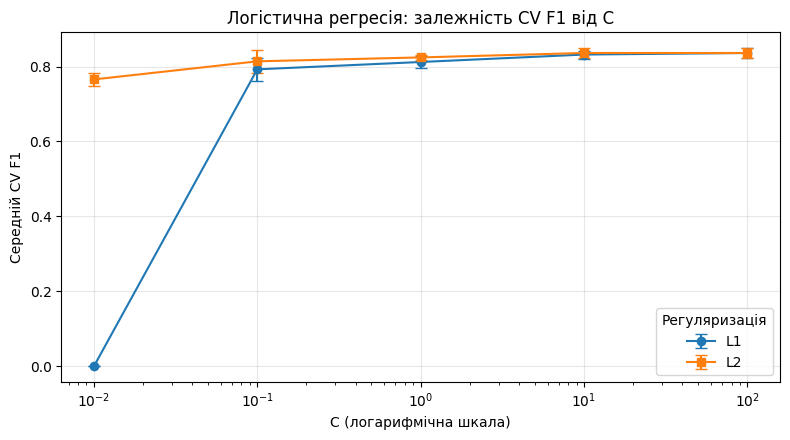

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for reg, marker in [("L1", "o"), ("L2", "s")]:
    part = lr_grid[lr_grid["Регуляризація"] == reg]
    ax.errorbar(part["C"], part["CV F1"], yerr=part["CV F1 std"],
                marker=marker, capsize=4, label=reg)
ax.set_xscale("log")
ax.set_xlabel("C (логарифмічна шкала)")
ax.set_ylabel("Середній CV F1")
ax.set_title("Логістична регресія: залежність CV F1 від C")
ax.grid(alpha=0.3)
ax.legend(title="Регуляризація")
plt.tight_layout()
plt.show()

In [13]:
best_lr_row = lr_grid.sort_values(
    ["CV F1", "CV F1 std"], ascending=[False, True]
).iloc[0]
BEST_LR_REG = best_lr_row["Регуляризація"].lower()
BEST_LR_C = float(best_lr_row["C"])
BEST_LR_C = int(BEST_LR_C) if BEST_LR_C.is_integer() else BEST_LR_C

ties = lr_grid[
    (lr_grid["CV F1"].round(4) == round(best_lr_row["CV F1"], 4))
    & (lr_grid["CV F1 std"].round(4) == round(best_lr_row["CV F1 std"], 4))
]
print("Конфігурації з однаковим найкращим CV F1 і std:")
display(ties[["Регуляризація", "C", "CV F1", "CV F1 std", "CV ROC AUC"]].round(4))

best_lr_pipeline = make_pipeline(
    make_logreg(BEST_LR_REG, BEST_LR_C, solver="liblinear")
)
print("Найкраща логістична регресія за CV:")
print(f"  регуляризація = {BEST_LR_REG.upper()}, C = {BEST_LR_C}, solver = liblinear")
print(f"  CV F1 = {best_lr_row['CV F1']:.4f} +/- {best_lr_row['CV F1 std']:.4f}")
print(f"  CV ROC AUC = {best_lr_row['CV ROC AUC']:.4f}")

Конфігурації з однаковим найкращим CV F1 і std:


,Регуляризація,C,CV F1,CV F1 std,CV ROC AUC
4,L1,100.0,0.8363,0.0127,0.8974
8,L2,10.0,0.8363,0.0127,0.9002
9,L2,100.0,0.8363,0.0127,0.8977


Найкраща логістична регресія за CV:
  регуляризація = L1, C = 100, solver = liblinear
  CV F1 = 0.8363 +/- 0.0127
  CV ROC AUC = 0.8974


### 8. Інтерпретація коефіцієнтів найкращої логістичної регресії

In [14]:
best_lr_pipeline.fit(X_train, y_train)
feature_names = best_lr_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefs = best_lr_pipeline.named_steps["classifier"].coef_[0]

coef_table = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefs,
    "|Коефіцієнт|": np.abs(coefs)
}).sort_values("|Коефіцієнт|", ascending=False)
coef_table["Вплив на log-odds класу 1"] = np.where(
    coef_table["Коефіцієнт"] > 0, "збільшує", "зменшує"
)
print("Ненульових коефіцієнтів:", int((coefs != 0).sum()), "з", len(coefs))
display(coef_table.head(5).round(4).reset_index(drop=True))

Ненульових коефіцієнтів: 24 з 28


,Ознака,Коефіцієнт,|Коефіцієнт|,Вплив на log-odds класу 1
0,cat__ca_0.0,-2.2106,2.2106,зменшує
1,cat__thal_7.0,1.4826,1.4826,збільшує
2,cat__restecg_1.0,-1.4537,1.4537,зменшує
3,cat__sex_0.0,-1.4226,1.4226,зменшує
4,cat__cp_4.0,1.3093,1.3093,збільшує


**Інтерпретація коефіцієнтів.** Числові ознаки стандартизовано, а категоріальні
закодовано one-hot, тому коефіцієнти можна порівнювати за модулем.
Найбільший вплив мають `ca_0.0` (відсутність забарвлених судин, від'ємний
коефіцієнт, зменшує log-odds класу 1), `thal_7.0` (оборотний дефект, додатний,
збільшує log-odds), `restecg_1.0` (від'ємний), `sex_0.0` (жіноча стать, від'ємний)
та `cp_4.0` (безсимптомний тип болю в грудях, додатний). Знак показує напрям зміни
log-odds позитивного класу за інших рівних умов. L1-регуляризація обнулила 4
коефіцієнти з 28. Ці коефіцієнти описують статистичний зв'язок у навчальних даних
і не доводять причинно-наслідкового або медичного впливу.

### 9. Висновок до практичної роботи 4

- Дані перевірено: 303 об'єкти, 13 ознак (5 числових, 8 категоріальних), 6 пропусків у `ca` і `thal`, класи 0 і 1 майже збалансовані (54.1 % і 45.9 %).
- Виконано один стратифікований поділ 80/20 (242 train, 61 test) з random_state=42, створено єдину StratifiedKFold(5).
- Імпутація, масштабування та one-hot-кодування знаходяться всередині ColumnTransformer у Pipeline і навчаються лише на train-частині кожного фолду.
- Масштабування не змінило CV F1, але зменшило кількість ітерацій оптимізатора з 1238 до 18.
- Мале C (0.01) означає дуже сильну регуляризацію: L1 обнулила всі коефіцієнти і модель завжди прогнозує клас 0 (F1 = 0), L2 дала лише 0.7658. Зі зростанням C якість зростає і стабілізується на рівні CV F1 = 0.8363 для C = 10 і 100.
- Конфігурації L1 C=100, L2 C=10 і L2 C=100 мають однаковий CV F1 = 0.8363 і std = 0.0127. Обрано L1, C=100, solver=liblinear, бо вона обнуляє 4 коефіцієнти і є простішою для інтерпретації.
- X_test і y_test не використовувалися.

# ЧАСТИНА II. ПРАКТИЧНА РОБОТА 5
## k-NN та ймовірнісні методи класифікації

Використовуються те саме розбиття train/test, той самий препроцесинг і та сама
StratifiedKFold, що й у практичній роботі 4. X_test і y_test залишаються закритими.

### 10. k-NN: вплив масштабування

In [15]:
rows = []
for scale in [False, True]:
    name = "k-NN зі StandardScaler" if scale else "k-NN без масштабування"
    pipe = make_pipeline(KNeighborsClassifier(n_neighbors=5), scale=scale)
    rows.append(evaluate_cv(name, pipe, "k=5, euclidean"))
knn_scaling = pd.DataFrame(rows)
display(knn_scaling[["Модель", "CV F1", "CV F1 std", "CV ROC AUC", "CV Recall"]].round(4))

ranges = X_train[numeric_columns].agg(["min", "max"]).T
ranges["Діапазон"] = ranges["max"] - ranges["min"]
display(ranges.round(1))

,Модель,CV F1,CV F1 std,CV ROC AUC,CV Recall
0,k-NN без масштабування,0.5120,0.0134,0.6419,0.4866
1,k-NN зі StandardScaler,0.7989,0.0426,0.8712,0.7826


,min,max,Діапазон
age,29.0,77.0,48.0
trestbps,94.0,200.0,106.0
chol,126.0,564.0,438.0
thalach,71.0,202.0,131.0
oldpeak,0.0,6.2,6.2


**Вплив масштабування на k-NN.** Без масштабування CV F1 становить лише 0.5120,
а зі StandardScaler 0.7989. k-NN порівнює об'єкти за відстанню, а діапазони ознак
дуже різні: `chol` змінюється на 438 одиниць, `trestbps` на 106, а `oldpeak`
лише на 6.2. Без масштабування відстань фактично визначається холестерином і
тиском, а one-hot-ознаки (0 або 1) майже не впливають. Стандартизація вирівнює
внесок числових ознак, тому для k-NN вона обов'язкова.

### 11. Вибір кількості сусідів k

,k,CV F1,CV F1 std,CV ROC AUC,CV Recall
0,3,0.8042,0.0272,0.8709,0.8008
1,5,0.7989,0.0426,0.8712,0.7826
2,7,0.7942,0.0184,0.8721,0.7656
3,9,0.7872,0.0294,0.8744,0.7557
4,11,0.7791,0.0273,0.8806,0.7375
5,15,0.7651,0.0246,0.8729,0.7209


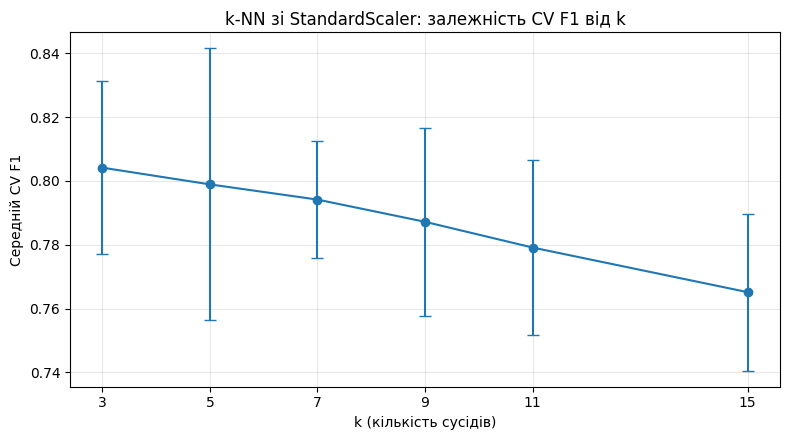

Найкраще k за CV F1: 3


In [16]:
K_VALUES = [3, 5, 7, 9, 11, 15]
rows = []
for k in K_VALUES:
    pipe = make_pipeline(KNeighborsClassifier(n_neighbors=k))
    row = evaluate_cv("k-NN", pipe, f"k={k}")
    row["k"] = k
    rows.append(row)
knn_k = pd.DataFrame(rows)
display(knn_k[["k", "CV F1", "CV F1 std", "CV ROC AUC", "CV Recall"]].round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(knn_k["k"], knn_k["CV F1"], yerr=knn_k["CV F1 std"],
            marker="o", capsize=4)
ax.set_xticks(K_VALUES)
ax.set_xlabel("k (кількість сусідів)")
ax.set_ylabel("Середній CV F1")
ax.set_title("k-NN зі StandardScaler: залежність CV F1 від k")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_k_row = knn_k.sort_values(["CV F1", "CV F1 std"], ascending=[False, True]).iloc[0]
BEST_K = int(best_k_row["k"])
print("Найкраще k за CV F1:", BEST_K)

### 12. Міри відстані для найкращого k

In [17]:
rows = []
for metric, title in [("euclidean", "Евклідова"), ("manhattan", "Мангеттенська")]:
    pipe = make_pipeline(KNeighborsClassifier(n_neighbors=BEST_K, metric=metric))
    row = evaluate_cv("k-NN", pipe, f"k={BEST_K}, {metric}")
    row["Міра відстані"] = title
    row["metric"] = metric
    rows.append(row)
knn_metric = pd.DataFrame(rows)
display(knn_metric[["Міра відстані", "CV F1", "CV F1 std", "CV ROC AUC"]].round(4))

best_metric_row = knn_metric.sort_values(["CV F1", "CV F1 std"], ascending=[False, True]).iloc[0]
BEST_KNN_METRIC = best_metric_row["metric"]
best_knn_pipeline = make_pipeline(
    KNeighborsClassifier(n_neighbors=BEST_K, metric=BEST_KNN_METRIC)
)
print(f"Найкраща k-NN: k={BEST_K}, metric={BEST_KNN_METRIC}, CV F1={best_metric_row['CV F1']:.4f}")

,Міра відстані,CV F1,CV F1 std,CV ROC AUC
0,Евклідова,0.8042,0.0272,0.8709
1,Мангеттенська,0.8175,0.0304,0.8768


Найкраща k-NN: k=3, metric=manhattan, CV F1=0.8175


**Вибір k і міри відстані.** Найкращий CV F1 = 0.8042 отримано для k = 3, далі зі
зростанням k якість поступово знижується до 0.7651 при k = 15: велике k згладжує
локальну структуру і модель недонавчається. Мале k більш чутливе до шуму, але на
цих даних воно дало кращий результат. Для k = 3 мангеттенська відстань
(CV F1 = 0.8175, ROC AUC = 0.8768) виявилася кращою за евклідову (0.8042), бо
менш чутлива до великих відхилень окремих ознак. Найкраща k-NN: k = 3, metric = manhattan.

### 13. Gaussian Naive Bayes: описовий аналіз розподілів ознак за класами

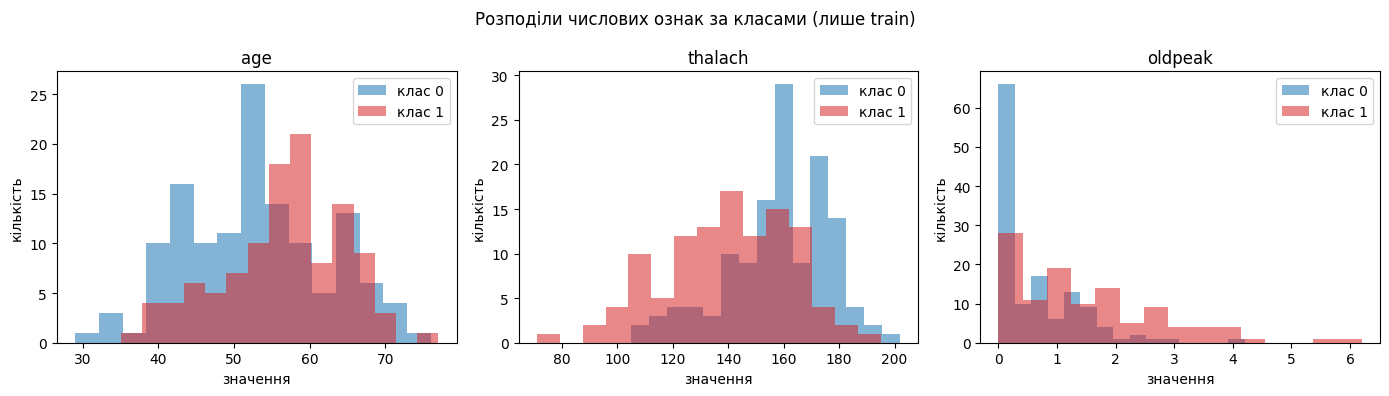

age             thalach              oldpeak            
         mean   std  skew    mean    std  skew    mean   std  skew
target                                                            
0       52.82  9.41  0.10  158.50  18.60 -0.62    0.59  0.76  1.60
1       56.59  8.06 -0.45  139.89  23.02 -0.34    1.48  1.28  1.02

In [18]:
train_df = X_train.assign(target=y_train)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["age", "thalach", "oldpeak"]):
    for cls, color in [(0, "tab:blue"), (1, "tab:red")]:
        ax.hist(train_df.loc[train_df["target"] == cls, col], bins=15,
                alpha=0.55, color=color, label=f"клас {cls}")
    ax.set_title(col)
    ax.set_xlabel("значення")
    ax.set_ylabel("кількість")
    ax.legend()
fig.suptitle("Розподіли числових ознак за класами (лише train)")
plt.tight_layout()
plt.show()

display(train_df.groupby("target")[["age", "thalach", "oldpeak"]].agg(["mean", "std", "skew"]).round(2))

**Описовий аналіз для GaussianNB.** Розподіли `age` і `thalach` в обох класах
наближено симетричні і схожі на нормальні, класи помітно зсунуті: у класі 1 вищий
вік і нижча максимальна частота серцевих скорочень. `oldpeak` має сильну
правосторонню асиметрію (skew 1.6 і 1.0) і багато нулів, тож припущення
нормальності для неї порушується. Крім того, після one-hot-кодування ознаки
залежні між собою, що порушує припущення умовної незалежності GaussianNB.

### 14. GaussianNB, LDA і QDA у окремих Pipeline; стабільність QDA

In [19]:
prob_rows = [
    evaluate_cv("GaussianNB", make_pipeline(GaussianNB()), "-"),
    evaluate_cv("LDA", make_pipeline(LinearDiscriminantAnalysis()), "solver=svd")
]

# Діагностика: ранг коваріаційної матриці кожного класу після препроцесингу (лише train)
Xt = make_preprocessor().fit_transform(X_train)
for cls in [0, 1]:
    Xc = Xt[y_train.values == cls]
    rank = np.linalg.matrix_rank(np.cov(Xc, rowvar=False))
    print(f"Клас {cls}: об'єктів = {len(Xc)}, ознак = {Xt.shape[1]}, ранг коваріаційної матриці = {rank}")
print()

qda_rows = []
for reg in [0.0, 0.01, 0.1]:
    pipe = make_pipeline(QuadraticDiscriminantAnalysis(reg_param=reg))
    try:
        row = evaluate_cv("QDA", pipe, f"reg_param={reg}")
        msgs = row["Тексти попереджень"]
        status = ("попередження: " + "; ".join(msgs)) if msgs else "без попереджень"
    except Exception as err:
        row = {"Модель": "QDA", "Параметри": f"reg_param={reg}",
               "CV F1": np.nan, "CV F1 std": np.nan, "CV ROC AUC": np.nan}
        status = f"навчання неможливе: {type(err).__name__}: {str(err).split('.')[0]}"
    row["reg_param"] = reg
    row["Стан QDA"] = status
    qda_rows.append(row)

qda_table = pd.DataFrame(qda_rows)
display(qda_table[["reg_param", "CV F1", "CV F1 std", "CV ROC AUC"]].round(4))
for _, r in qda_table.iterrows():
    print(f"reg_param={r['reg_param']}: {r['Стан QDA']}")

Клас 0: об'єктів = 131, ознак = 28, ранг коваріаційної матриці = 20
Клас 1: об'єктів = 111, ознак = 28, ранг коваріаційної матриці = 19



,reg_param,CV F1,CV F1 std,CV ROC AUC
0,0.00,0.5709,0.1433,0.7607
1,0.01,0.7709,0.0440,0.8343
2,0.10,0.7962,0.0271,0.8680


reg_param=0.0: попередження: LinAlgWarning: The covariance matrix of class 0 is not full rank; LinAlgWarning: The covariance matrix of class 1 is not full rank
reg_param=0.01: без попереджень
reg_param=0.1: без попереджень


In [20]:
best_qda_row = qda_table.sort_values(["CV F1", "CV F1 std"], ascending=[False, True]).iloc[0]
BEST_QDA_REG = float(best_qda_row["reg_param"])
prob_rows.append(qda_table[qda_table["reg_param"] == BEST_QDA_REG].iloc[0].to_dict())

knn_best_row = evaluate_cv("k-NN", best_knn_pipeline, f"k={BEST_K}, {BEST_KNN_METRIC}")
pr5_table = pd.DataFrame([knn_best_row] + prob_rows)
display(pr5_table[["Модель", "Параметри", "CV F1", "CV F1 std", "CV ROC AUC", "CV Recall", "Час навчання, с"]].round(4))

best_prob_row = pd.DataFrame(prob_rows).sort_values(["CV F1", "CV F1 std"], ascending=[False, True]).iloc[0]
BEST_PROB_NAME = best_prob_row["Модель"]
print("Найкраща ймовірнісна модель за CV F1:", BEST_PROB_NAME, best_prob_row["Параметри"])

,Модель,Параметри,CV F1,CV F1 std,CV ROC AUC,CV Recall,"Час навчання, с"
0,k-NN,"k=3, manhattan",0.8175,0.0304,0.8768,0.7917,0.0203
1,GaussianNB,-,0.7495,0.0215,0.8773,0.8458,0.0503
2,LDA,solver=svd,0.8128,0.0257,0.8993,0.7656,0.0448
3,QDA,reg_param=0.1,0.7962,0.0271,0.8680,0.7743,0.0190


Найкраща ймовірнісна модель за CV F1: LDA solver=svd


**Стабільність QDA і порівняння.** Після препроцесингу є 28 ознак, а ранг
коваріаційної матриці класу 0 дорівнює лише 20, класу 1 лише 19, тобто матриці
вироджені. Причина в one-hot-кодуванні (стовпці кожної категоріальної ознаки в сумі
дають 1) і в рідкісних категоріях, які в межах класу майже не змінюються. QDA
обертає окрему коваріаційну матрицю для кожного класу, тому без регуляризації
(reg_param = 0) вона нестабільна: у scikit-learn 1.6 (Colab) модель формально
навчається, але CV F1 = 0.5709 з дуже великим розкидом між фолдами (std 0.1433)
і CV ROC AUC лише 0.7607; у новіших версіях scikit-learn таке навчання завершується
помилкою LinAlgError. Регуляризація reg_param = 0.01 і 0.1 усуває проблему;
найкращий результат дає reg_param = 0.1 (CV F1 = 0.7962, std 0.0271).
Серед імовірнісних моделей найкраща LDA: CV F1 = 0.8128 і найвищий CV ROC AUC = 0.8993.
GaussianNB має найвищий recall (0.8458), але найнижчий F1 (0.7495) через багато
хибних тривог.

### 15. Позавибіркові ймовірності для кількох об'єктів train

In [21]:
oof_models = {
    "GaussianNB OOF": make_pipeline(GaussianNB()),
    "LDA OOF": make_pipeline(LinearDiscriminantAnalysis()),
    f"QDA OOF (reg={BEST_QDA_REG})": make_pipeline(QuadraticDiscriminantAnalysis(reg_param=BEST_QDA_REG))
}
oof = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # попередження QDA вже зафіксовано вище
    for name, pipe in oof_models.items():
        oof[name] = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rng = np.random.RandomState(RANDOM_STATE)
idx0 = rng.choice(np.where(y_train.values == 0)[0], 3, replace=False)
idx1 = rng.choice(np.where(y_train.values == 1)[0], 3, replace=False)
sample_pos = np.concatenate([idx0, idx1])

oof_table = pd.DataFrame({
    "Об'єкт train (індекс)": X_train.index[sample_pos],
    "Справжній клас": y_train.values[sample_pos]
})
for name, proba in oof.items():
    oof_table[name] = proba[sample_pos].round(3)
display(oof_table)

,Об'єкт train (індекс),Справжній клас,GaussianNB OOF,LDA OOF,QDA OOF (reg=0.1)
0,150,0,0.999,0.238,0.911
1,48,0,0.967,0.049,0.010
2,39,0,0.001,0.351,0.873
3,294,1,0.995,0.117,0.005
4,36,1,1.000,0.965,0.998
5,236,1,1.000,0.933,0.999


**Позавибіркові ймовірності.** Кожну ймовірність отримано моделлю, яка не бачила
цей об'єкт під час навчання. GaussianNB і QDA дуже часто дають крайні значення
(0.999, 0.001), навіть коли помиляються (об'єкти 150 і 294). Це наслідок порушення
припущень: залежні one-hot-ознаки множаться як незалежні, і впевненість
перебільшується. LDA дає поміркованіші ймовірності (0.05-0.35 для класу 0) і
помиляється рідше, тому її ймовірності краще відображають реальну невизначеність.

### 16. Висновок до практичної роботи 5

- Масштабування для k-NN критично важливе: CV F1 зріс з 0.5120 до 0.7989.
- Найкраща k-NN за CV: k = 3, мангеттенська відстань, CV F1 = 0.8175, CV ROC AUC = 0.8768.
- GaussianNB має високий recall, але низьку precision; її припущення (нормальність і незалежність ознак) на цих даних порушуються.
- QDA без регуляризації нестабільна: коваріаційні матриці класів вироджені (ранг 20 і 19 при 28 ознаках), CV F1 = 0.5709 +/- 0.1433; з reg_param = 0.1 працює стабільно (0.7962 +/- 0.0271), але поступається LDA.
- Найкраща ймовірнісна модель: LDA (CV F1 = 0.8128, CV ROC AUC = 0.8993); спільна коваріаційна матриця має менше параметрів і стабільніша на 242 об'єктах.
- Усі моделі є частиною Pipeline, використано ту саму StratifiedKFold, X_test і y_test не відкривалися.

# ЧАСТИНА III. ПРАКТИЧНА РОБОТА 6
## Метод опорних векторів і пошук гіперпараметрів

SVM навчається на масштабованих числових ознаках усередині того самого Pipeline.
GridSearchCV працює лише з X_train і y_train.

### 17. Лінійна SVM для C = 0.1, 1, 10

In [22]:
rows = []
for C in [0.1, 1, 10]:
    pipe = make_pipeline(SVC(kernel="linear", C=C))
    row = evaluate_cv("Linear SVM", pipe, f"C={C}")
    row["C"] = C
    rows.append(row)
linear_svm = pd.DataFrame(rows)
display(linear_svm[["C", "CV F1", "CV F1 std", "CV ROC AUC", "CV Recall", "Час навчання, с"]].round(4))

,C,CV F1,CV F1 std,CV ROC AUC,CV Recall,"Час навчання, с"
0,0.1,0.7962,0.0536,0.9047,0.7375,0.0231
1,1.0,0.8025,0.0309,0.8980,0.7747,0.0216
2,10.0,0.8000,0.0263,0.8968,0.7747,0.0340


**Лінійна SVM.** Для C = 0.1 модель має найвищий CV ROC AUC (0.9047), але
найнижчий recall і найбільший розкид F1 (std 0.0536): широка смуга допускає
багато помилок на межі. Найкращий CV F1 = 0.8025 при C = 1; при C = 10 якість
майже не змінюється (0.8000). Отже, для лінійного ядра оптимальне помірне C = 1.

### 18. SVM із RBF-ядром і пошук гіперпараметрів GridSearchCV

- **C** контролює силу штрафу за помилки на навчальних даних: мале C дає ширшу смугу і більше помилок, велике C намагається класифікувати train майже без помилок.
- **gamma** контролює локальність впливу окремого навчального об'єкта: мале gamma формує гладку межу, велике gamma робить межу дуже складною і може призвести до перенавчання.
- Параметр gamma задається лише для RBF, для лінійного ядра він не використовується.

In [23]:
svm_pipeline = make_pipeline(SVC())

param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    }
]

svm_search = GridSearchCV(
    svm_pipeline,
    param_grid=param_grid,
    scoring=SCORING,
    refit=PRIMARY_METRIC,
    cv=cv,
    n_jobs=-1
)
svm_search.fit(X_train, y_train)

print("Найкращі параметри:", svm_search.best_params_)
print(f"Найкращий CV F1: {svm_search.best_score_:.4f}")

Найкращі параметри: {'classifier__C': 10, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
Найкращий CV F1: 0.8270


In [24]:
svm_results = pd.DataFrame(svm_search.cv_results_)
svm_results["kernel"] = svm_results["param_classifier__kernel"]
svm_results["C"] = svm_results["param_classifier__C"]
svm_results["gamma"] = svm_results["param_classifier__gamma"].fillna("-")
svm_top = svm_results.sort_values(["rank_test_f1", "std_test_f1"])[[
    "rank_test_f1", "kernel", "C", "gamma",
    "mean_test_f1", "std_test_f1", "mean_test_roc_auc", "mean_test_recall", "mean_fit_time"
]].rename(columns={
    "rank_test_f1": "Ранг",
    "mean_test_f1": "CV F1",
    "std_test_f1": "CV F1 std",
    "mean_test_roc_auc": "CV ROC AUC",
    "mean_test_recall": "CV Recall",
    "mean_fit_time": "Час навчання, с"
})
display(svm_top.head(6).round(4).reset_index(drop=True))

,Ранг,kernel,C,gamma,CV F1,CV F1 std,CV ROC AUC,CV Recall,"Час навчання, с"
0,1,rbf,10.0,0.01,0.8270,0.0330,0.8968,0.7830,0.0434
1,2,linear,1.0,-,0.8025,0.0309,0.8980,0.7747,0.0344
2,3,linear,10.0,-,0.8000,0.0263,0.8968,0.7747,0.0479
3,4,linear,0.1,-,0.7962,0.0536,0.9047,0.7375,0.0390
4,5,rbf,1.0,0.01,0.7951,0.0292,0.8957,0.7561,0.0353
5,6,rbf,1.0,scale,0.7893,0.0271,0.8884,0.7648,0.0368


In [25]:
best_by_kernel = (
    svm_top.sort_values(["CV F1", "CV F1 std"], ascending=[False, True])
    .groupby("kernel", as_index=False).first()
)
display(best_by_kernel.round(4))

rbf_part = svm_results[svm_results["kernel"] == "rbf"].pivot_table(
    index="C", columns="gamma", values="mean_test_f1"
)
print("CV F1 для RBF-SVM (рядки C, стовпці gamma):")
display(rbf_part.round(4))

BEST_SVM_PARAMS = {k.replace("classifier__", ""): v for k, v in svm_search.best_params_.items()}
best_svm_pipeline = make_pipeline(SVC(**BEST_SVM_PARAMS))
print("Найкраща конфігурація SVM:", BEST_SVM_PARAMS)

,kernel,Ранг,C,gamma,CV F1,CV F1 std,CV ROC AUC,CV Recall,"Час навчання, с"
0,linear,2,1.0,-,0.8025,0.0309,0.8980,0.7747,0.0344
1,rbf,1,10.0,0.01,0.8270,0.0330,0.8968,0.7830,0.0434


CV F1 для RBF-SVM (рядки C, стовпці gamma):


gamma,0.01,0.1,scale
C,,,
0.1,0.2461,0.7652,0.7630
1.0,0.7951,0.7893,0.7893
10.0,0.8270,0.7558,0.7480


Найкраща конфігурація SVM: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}


**Результати GridSearchCV.** Найкраща конфігурація: kernel = rbf, C = 10,
gamma = 0.01, CV F1 = 0.8270, CV ROC AUC = 0.8968. Вона краща за найкращу лінійну
SVM (C = 1, CV F1 = 0.8025) за F1 і recall, а за ROC AUC вони майже однакові.
Таблиця RBF показує взаємодію параметрів: при малому gamma = 0.01 і малому C = 0.1
модель надто проста (F1 = 0.2461, майже завжди прогнозує клас 0), а при більшому
gamma = 0.1 збільшення C до 10 знижує F1 до 0.7558, що є ознакою перенавчання
через надто складну межу. Найкращий баланс дає гладка межа (мале gamma) з
сильнішим штрафом за помилки (C = 10).

### 19. Висновок до практичної роботи 6

- Linear SVM і RBF-SVM побудовано в Pipeline з масштабуванням числових ознак.
- Для linear SVM найкраще C = 1 (CV F1 = 0.8025).
- Параметрична сітка коректна: gamma задається лише для RBF.
- GridSearchCV з тією самою StratifiedKFold і основною метрикою F1 визначив найкращу конфігурацію: rbf, C = 10, gamma = 0.01 (CV F1 = 0.8270, std 0.0330, CV ROC AUC = 0.8968).
- C керує компромісом між шириною смуги і помилками на train, gamma керує локальністю впливу об'єктів; надто мале C з малим gamma дає недонавчання, велике gamma з великим C дає перенавчання.
- Час навчання обох варіантів SVM дуже малий (соті частки секунди на фолд), тому він не впливає на вибір; test не використовувався.

# ЧАСТИНА IV. ПРАКТИЧНА РОБОТА 7
## Порівняння моделей, фінальне тестування і збереження Pipeline

Спочатку всі кандидати порівнюються лише на train через позавибіркові прогнози
та крос-валідацію. Тестова вибірка відкривається один раз і лише для
зафіксованої фінальної моделі.

### 20. Кандидати з практичних робіт 4-6

In [26]:
candidates = {
    "Logistic Regression": (
        best_lr_pipeline,
        f"{BEST_LR_REG.upper()}, C={BEST_LR_C}, solver=liblinear"
    ),
    "k-NN": (
        best_knn_pipeline,
        f"k={BEST_K}, metric={BEST_KNN_METRIC}"
    ),
    "GaussianNB": (make_pipeline(GaussianNB()), "-"),
    "LDA": (make_pipeline(LinearDiscriminantAnalysis()), "solver=svd"),
    "QDA": (
        make_pipeline(QuadraticDiscriminantAnalysis(reg_param=BEST_QDA_REG)),
        f"reg_param={BEST_QDA_REG}"
    ),
    "SVM": (
        best_svm_pipeline,
        ", ".join(f"{k}={v}" for k, v in BEST_SVM_PARAMS.items())
    )
}
for name, (_, params) in candidates.items():
    print(f"{name:20s} {params}")

Logistic Regression  L1, C=100, solver=liblinear
k-NN                 k=3, metric=manhattan
GaussianNB           -
LDA                  solver=svd
QDA                  reg_param=0.1
SVM                  C=10, gamma=0.01, kernel=rbf


### 21. Крос-валідаційні ROC-криві кандидатів (позавибіркові прогнози train)

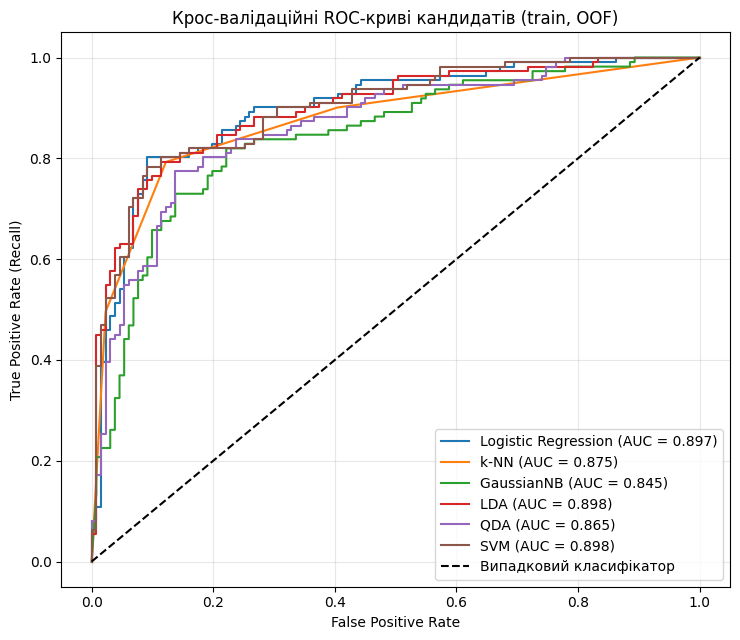

,Модель,OOF ROC AUC (train)
5,SVM,0.8982
3,LDA,0.8979
0,Logistic Regression,0.8974
1,k-NN,0.8747
4,QDA,0.8655
2,GaussianNB,0.8450


In [27]:
oof_scores = {}
oof_preds = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, (pipe, _) in candidates.items():
        method = "decision_function" if name == "SVM" else "predict_proba"
        scores = cross_val_predict(pipe, X_train, y_train, cv=cv, method=method)
        oof_scores[name] = scores if method == "decision_function" else scores[:, 1]
        oof_preds[name] = cross_val_predict(pipe, X_train, y_train, cv=cv)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
roc_rows = []
for name, scores in oof_scores.items():
    fpr, tpr, _ = roc_curve(y_train, scores, pos_label=POSITIVE_CLASS)
    auc = roc_auc_score(y_train, scores)
    roc_rows.append({"Модель": name, "OOF ROC AUC (train)": auc})
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Випадковий класифікатор")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_title("Крос-валідаційні ROC-криві кандидатів (train, OOF)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
display(pd.DataFrame(roc_rows).sort_values("OOF ROC AUC (train)", ascending=False).round(4))

**ROC-криві кандидатів.** Криві SVM, LDA і логістичної регресії майже збігаються
і розташовані найближче до лівого верхнього кута (OOF ROC AUC 0.898, 0.898 і 0.897).
Нижче розташовані k-NN (0.875), QDA (0.865) і GaussianNB (0.845). Чим ближче крива
до лівого верхнього кута і чим більший AUC, тим краще модель ранжує хворих пацієнтів
вище за здорових. Ці криві побудовано лише на train і використовуються лише для
порівняння кандидатів.

### 22. CV-матриці помилок до фінального тестування

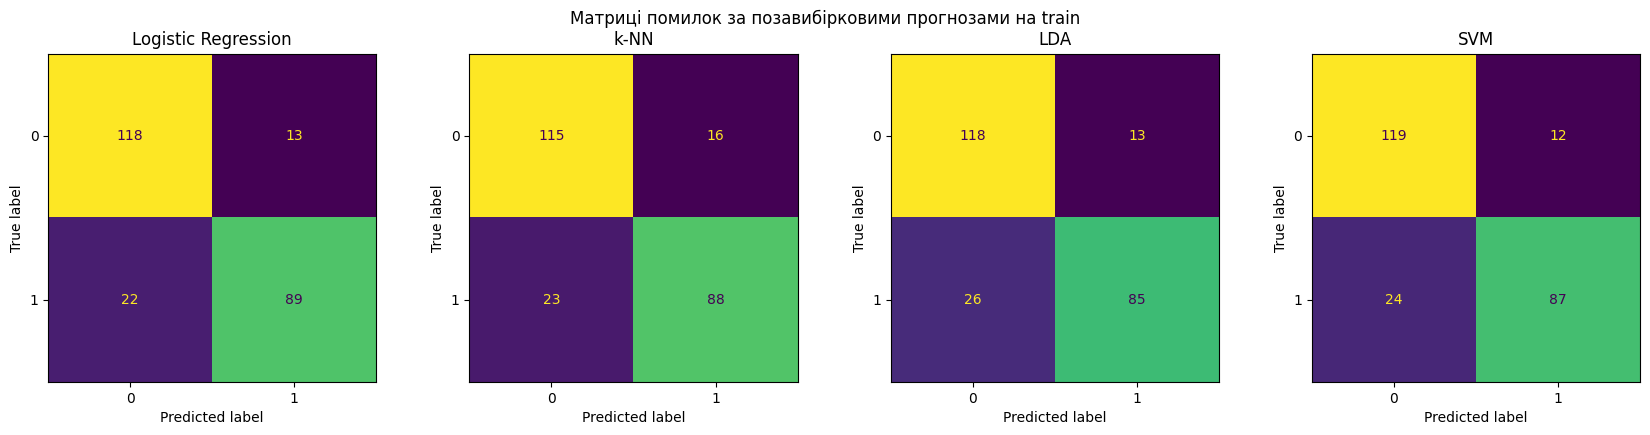

,Модель,TN,FP,FN,TP,Правильних,Recall класу 1
0,Logistic Regression,118,13,22,89,207,0.802
1,k-NN,115,16,23,88,203,0.793
2,LDA,118,13,26,85,203,0.766
3,SVM,119,12,24,87,206,0.784


In [28]:
cm_models = ["Logistic Regression", "k-NN", BEST_PROB_NAME, "SVM"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
cm_rows = []
for ax, name in zip(axes, cm_models):
    cm = confusion_matrix(y_train, oof_preds[name])
    ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
    tn, fp, fn, tp = cm.ravel()
    cm_rows.append({"Модель": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                    "Правильних": tn + tp, "Recall класу 1": tp / (tp + fn)})
fig.suptitle("Матриці помилок за позавибірковими прогнозами на train")
plt.tight_layout()
plt.show()
display(pd.DataFrame(cm_rows).round(3))

**CV-матриці помилок.** Логістична регресія має найбільше правильних прогнозів
(207 з 242) і найменше пропущених хворих (FN = 22, recall 0.802). SVM має найменше
хибних тривог (FP = 12), але пропускає 24 хворих. LDA пропускає найбільше
позитивних об'єктів (FN = 26). Для медичної задачі пропуск хворого (FN)
небезпечніший, тому кращою є модель з меншим FN.

### 23. Підсумкова таблиця кандидатів (лише CV-метрики)

In [29]:
rows = []
for name, (pipe, params) in candidates.items():
    rows.append(evaluate_cv(name, pipe, params))
cv_comparison = pd.DataFrame(rows)[[
    "Модель", "Параметри", "CV F1", "CV F1 std", "CV Recall",
    "CV ROC AUC", "CV Precision", "CV Accuracy", "Час навчання, с", "Час прогнозу, с"
]].rename(columns={"Параметри": "Найкращі параметри"})

cv_comparison = cv_comparison.sort_values("CV F1", ascending=False).reset_index(drop=True)
cv_comparison.to_csv(CV_TABLE_PATH, index=False)
display(cv_comparison.round(4))
print("Збережено:", CV_TABLE_PATH)

,Модель,Найкращі параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,CV Precision,CV Accuracy,"Час навчання, с","Час прогнозу, с"
0,Logistic Regression,"L1, C=100, solver=liblinear",0.8363,0.0127,0.8016,0.8974,0.8781,0.8554,0.0553,0.0496
1,SVM,"C=10, gamma=0.01, kernel=rbf",0.8270,0.0330,0.7830,0.8968,0.8848,0.8511,0.0207,0.0305
2,k-NN,"k=3, metric=manhattan",0.8175,0.0304,0.7917,0.8768,0.8531,0.8386,0.0208,0.0338
3,LDA,solver=svd,0.8128,0.0257,0.7656,0.8993,0.8727,0.8387,0.0218,0.0331
4,QDA,reg_param=0.1,0.7962,0.0271,0.7743,0.8680,0.8265,0.8181,0.0194,0.0300
5,GaussianNB,-,0.7495,0.0215,0.8458,0.8773,0.7049,0.7438,0.0192,0.0305


Збережено: classification-mini-project/reports/cv_model_comparison.csv


In [30]:
# Застосування заздалегідь визначеного правила вибору
best_f1 = cv_comparison["CV F1"].max()
close = cv_comparison[cv_comparison["CV F1"] >= best_f1 - 0.01]
print("Кандидати в межах 0.01 від найкращого CV F1:")
display(close[["Модель", "CV F1", "CV F1 std", "CV Recall", "CV ROC AUC"]].round(4))
rule_choice = close.sort_values("CV F1 std").iloc[0]["Модель"]
print("Модель за правилом (найменший CV F1 std серед близьких):", rule_choice)

Кандидати в межах 0.01 від найкращого CV F1:


,Модель,CV F1,CV F1 std,CV Recall,CV ROC AUC
0,Logistic Regression,0.8363,0.0127,0.8016,0.8974
1,SVM,0.8270,0.0330,0.7830,0.8968


Модель за правилом (найменший CV F1 std серед близьких): Logistic Regression


**Обґрунтування вибору фінальної моделі.** Фінальною обрано логістичну регресію з
L1-регуляризацією (C = 100, solver = liblinear). Її середній CV F1 становив 0.8363,
що є найкращим результатом серед усіх кандидатів, а CV ROC AUC 0.8974 лише на 0.003
нижчий за найкращий (LDA). Стандартне відхилення F1 між фолдами 0.0127 найменше серед
кандидатів, що свідчить про стабільність моделі. Порівняно з другою за F1 моделлю
RBF-SVM (0.8270, std 0.0330) логістична регресія має вищий recall (0.8016 проти
0.7830) і менше пропущених хворих. Її перевагою є простота, швидкість та можливість
інтерпретувати коефіцієнти, а недоліком лінійна межа рішень, яка не враховує складних
взаємодій ознак. За сукупністю критеріїв модель зафіксовано як фінальну до оцінювання на test.

### Фіксація фінальної моделі (до відкриття test)

- **Алгоритм:** LogisticRegression у Pipeline з ColumnTransformer.
- **Гіперпараметри класифікатора:** L1-регуляризація, C = 100, solver = liblinear, max_iter = 2000, random_state = 42.
- **Препроцесинг:** числові ознаки: SimpleImputer(median) + StandardScaler; категоріальні: SimpleImputer(most_frequent) + OneHotEncoder(handle_unknown="ignore").
- **Підстава:** найкращий CV F1 = 0.8363 і найменший CV F1 std = 0.0127 за правилом, визначеним до експериментів.

Після цієї комірки модель не змінюється.

In [31]:
FINAL_MODEL_NAME = "Logistic Regression"
assert FINAL_MODEL_NAME == rule_choice, "Зафіксована модель не збігається з правилом"

final_pipeline, final_params = candidates[FINAL_MODEL_NAME]
print("Зафіксовано до відкриття test:")
print("  алгоритм:", FINAL_MODEL_NAME)
print("  гіперпараметри:", final_params)
final_pipeline

Зафіксовано до відкриття test:
  алгоритм: Logistic Regression
  гіперпараметри: L1, C=100, solver=liblinear


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal'])])),
                ('classifier',
                 LogisticRegression(C=100, max_iter=2000, penalty='l1',
                                    random_state=42, solver='liblinear'))])

### 24. Одноразове фінальне оцінювання на тестовій вибірці

In [32]:
final_pipeline.fit(X_train, y_train)

y_pred = final_pipeline.predict(X_test)
if hasattr(final_pipeline, "predict_proba"):
    y_score = final_pipeline.predict_proba(X_test)[:, 1]
    score_name = "P(клас 1)"
else:
    y_score = final_pipeline.decision_function(X_test)
    score_name = "decision_function"

final_metrics = pd.DataFrame([{
    "Фінальна модель": FINAL_MODEL_NAME,
    "Параметри": final_params,
    "Test Accuracy": accuracy_score(y_test, y_pred),
    "Test Precision": precision_score(y_test, y_pred, pos_label=POSITIVE_CLASS),
    "Test Recall": recall_score(y_test, y_pred, pos_label=POSITIVE_CLASS),
    "Test F1": f1_score(y_test, y_pred, pos_label=POSITIVE_CLASS),
    "Test ROC AUC": roc_auc_score(y_test, y_score)
}])
final_metrics.to_csv(TEST_METRICS_PATH, index=False)
display(final_metrics.round(4))

cv_row = cv_comparison[cv_comparison["Модель"] == FINAL_MODEL_NAME].iloc[0]
print(f"CV F1 = {cv_row['CV F1']:.4f} +/- {cv_row['CV F1 std']:.4f}, Test F1 = {final_metrics['Test F1'][0]:.4f}")
print(f"CV ROC AUC = {cv_row['CV ROC AUC']:.4f}, Test ROC AUC = {final_metrics['Test ROC AUC'][0]:.4f}")
print("Збережено:", TEST_METRICS_PATH)

,Фінальна модель,Параметри,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC AUC
0,Logistic Regression,"L1, C=100, solver=liblinear",0.8689,0.8333,0.8929,0.8621,0.9578


CV F1 = 0.8363 +/- 0.0127, Test F1 = 0.8621
CV ROC AUC = 0.8974, Test ROC AUC = 0.9578
Збережено: classification-mini-project/reports/final_test_metrics.csv


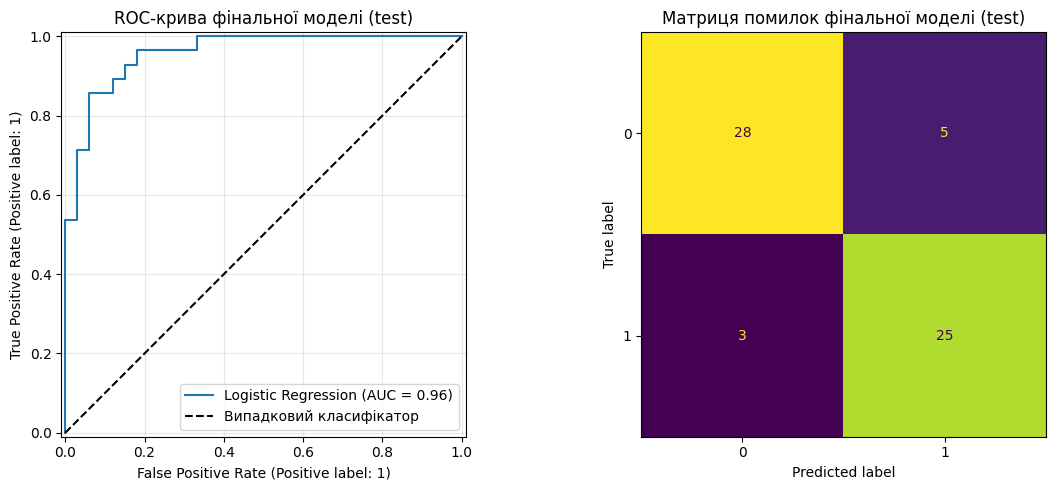

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_score, pos_label=POSITIVE_CLASS,
                                 name=FINAL_MODEL_NAME, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", label="Випадковий класифікатор")
axes[0].set_title("ROC-крива фінальної моделі (test)")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=[0, 1],
                                        ax=axes[1], colorbar=False)
axes[1].set_title("Матриця помилок фінальної моделі (test)")
plt.tight_layout()
plt.show()

**Результати на test.** Зафіксована модель на 61 тестовому об'єкті отримала
Accuracy = 0.8689, Precision = 0.8333, Recall = 0.8929, F1 = 0.8621, ROC AUC = 0.9578.
Test F1 (0.8621) трохи вищий за CV F1 (0.8363 +/- 0.0127), а Test ROC AUC (0.9578)
помітно вищий за CV ROC AUC (0.8974). Це не означає, що модель краща, ніж показала
крос-валідація: тестова вибірка мала (61 об'єкт), тому одна-дві зміни прогнозу
змінюють метрики на кілька відсотків. Результати узгоджуються з CV, ознак
перенавчання немає. Модель після перегляду test не змінюється.

### 25. Аналіз помилкових прогнозів фінальної моделі

In [34]:
errors = X_test.copy()
errors["Справжній клас"] = y_test
errors["Прогноз"] = y_pred
errors[score_name] = np.round(y_score, 3)
errors = errors[errors["Справжній клас"] != errors["Прогноз"]]
errors = errors.reset_index().rename(columns={"index": "Індекс"})
show_cols = ["Індекс", "Справжній клас", "Прогноз", score_name,
             "age", "sex", "cp", "thalach", "oldpeak", "exang", "ca", "thal"]
print("Неправильно класифікованих test-об'єктів:", len(errors), "з", len(y_test))
display(errors[show_cols])

Неправильно класифікованих test-об'єктів: 8 з 61


,Індекс,Справжній клас,Прогноз,P(клас 1),age,sex,cp,thalach,oldpeak,exang,ca,thal
0,271,0,1,0.500,66,1,4,138,2.3,0,0.0,6.0
1,196,0,1,0.712,69,1,1,131,0.1,0,1.0,3.0
2,33,0,1,0.790,59,1,4,161,0.5,0,0.0,7.0
3,292,1,0,0.390,44,1,4,144,2.8,1,0.0,6.0
4,287,0,1,0.609,58,1,2,144,0.4,0,NaN,7.0
5,66,1,0,0.249,60,1,3,155,3.0,0,0.0,3.0
6,92,0,1,0.935,62,1,3,146,1.8,0,3.0,7.0
7,172,1,0,0.467,59,0,4,143,0.0,1,0.0,3.0


**Аналіз помилок.** Модель помилилася на 8 з 61 тестових об'єктів: 5 хибних тривог
(FP) і 3 пропущені хворі (FN). Більшість помилок близькі до межі рішення:
ймовірності 0.500, 0.467, 0.390, 0.609 лежать біля порогу 0.5. Повторюються
суперечливі ознаки: 4 з 5 хибних тривог мають `thal` = 7 або `cp` = 4 (сильні
ознаки класу 1), але насправді здорові; усі 3 пропущені хворі мають `ca` = 0
(сильна ознака класу 0). Модель надто впевнена лише в одному випадку (об'єкт 92, P = 0.935 для
здорового пацієнта з `ca` = 3 і `thal` = 7). Аналіз виконано для пояснення
результату, модель не змінювалася.

### 26. Збереження та перевірка фінального Pipeline

In [35]:
joblib.dump(final_pipeline, MODEL_PATH)
print("Файл створено:", MODEL_PATH.exists(), "| розмір, байт:", MODEL_PATH.stat().st_size)

loaded_pipeline = joblib.load(MODEL_PATH)
check_prediction = loaded_pipeline.predict(X_test.head(3))
print("Тип збереженого об'єкта:", type(loaded_pipeline).__name__)
print("Кроки Pipeline:", list(loaded_pipeline.named_steps))
print("Прогноз для 3 сирих об'єктів X_test:", check_prediction)
assert (check_prediction == final_pipeline.predict(X_test.head(3))).all()

new_patient = X_test.head(1).copy()
new_patient["ca"] = np.nan  # пропуск обробляється всередині Pipeline
print("Прогноз для об'єкта з пропуском у ca:", loaded_pipeline.predict(new_patient))

Файл створено: True | розмір, байт: 4950
Тип збереженого об'єкта: Pipeline
Кроки Pipeline: ['preprocessor', 'classifier']
Прогноз для 3 сирих об'єктів X_test: [0 1 0]
Прогноз для об'єкта з пропуском у ca: [0]


In [36]:
for path in [LOCAL_DATA_PATH, CV_TABLE_PATH, TEST_METRICS_PATH, MODEL_PATH]:
    print(f"{str(path):55s} {'є' if path.exists() else 'немає (дані завантажено за URL)'}")

try:
    from google.colab import files
    archive = shutil.make_archive("classification_outputs", "zip", PROJECT_DIR)
    files.download(archive)
except ImportError:
    print("Запуск не в Colab, архів не завантажується.")

classification-mini-project/data/heart_disease.csv      немає (дані завантажено за URL)
classification-mini-project/reports/cv_model_comparison.csv є
classification-mini-project/reports/final_test_metrics.csv є
classification-mini-project/models/best_classifier.joblib є


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 27. Підсумкові висновки мініпроєкту

1. **Масштабування і логістична регресія.** StandardScaler не змінив CV F1 (0.8245), але зменшив кількість ітерацій оптимізатора з 1238 до 18 і трохи підвищив CV ROC AUC.
2. **Масштабування і k-NN.** Без масштабування CV F1 = 0.5120, з ним 0.7989: k-NN дуже чутливий до масштабу.
3. **Найкращі k і відстань.** k = 3, мангеттенська відстань (CV F1 = 0.8175).
4. **Найстабільніша ймовірнісна модель.** LDA (CV F1 = 0.8128, CV ROC AUC = 0.8993, std 0.0257).
5. **QDA.** Без регуляризації нестабільна (вироджені коваріаційні матриці класів, CV F1 = 0.5709 +/- 0.1433), з reg_param = 0.1 працює стабільно, але поступається LDA.
6. **Параметри SVM.** Обрано RBF-ядро, C = 10, gamma = 0.01 (CV F1 = 0.8270).
7. **Найкращі CV-метрики.** Найкращий CV F1 = 0.8363 має логістична регресія, найкращий середній CV ROC AUC = 0.8993 має LDA (OOF ROC AUC SVM, LDA і LR майже однакові, близько 0.898).
8. **Фінальна модель.** Логістична регресія (L1, C = 100, liblinear): найкращий CV F1, найменший розкид між фолдами, вищий recall, простота та інтерпретованість.
9. **Результати на test.** Accuracy = 0.8689, Precision = 0.8333, Recall = 0.8929, F1 = 0.8621, ROC AUC = 0.9578.
10. **Узгодженість.** Test-результат узгоджується з CV і навіть трохи вищий, що пояснюється малим розміром тестової вибірки, а не покращенням моделі.
11. **Обмеження.** Малий набір (303 об'єкти, 61 у test) дає велику невизначеність оцінок; дані одного джерела (Cleveland); перебрано невелику сітку параметрів; не використано nested CV; поріг класифікації 0.5 не налаштовувався під recall. Результати не є медичним діагнозом.